# Sentiment Analysis of Amazon Electronics Reviews — DistilBERT vs. BiLSTM + Word2Vec

This notebook merges two earlier notebooks into one clean pipeline:

| Source notebook | What it contributed |
|---|---|
| `ehsan_project_2(1).ipynb` | EDA (ratings, word clouds, top reviewers / products / brands), text cleaning, **DistilBERT** fine-tuning |
| `sentiment-analysis-of-comments.ipynb` | **Warranty / guarantee aspect analysis** with Word2Vec, **BiLSTM** classifier on Word2Vec embeddings |

**Goal:** compare a fine-tuned transformer (DistilBERT) to a classic recurrent baseline (BiLSTM + pretrained Word2Vec) on the **same** 3-class sentiment task (negative / neutral / positive).

**Why a fresh comparison?** The original numbers can't be compared directly:
* DistilBERT (notebook 1) used the **test** split to pick the best checkpoint, which leaks test data into model selection.
* The LSTM (notebook 2) trained only on warranty-related reviews. It mixed a binary label with a 5-class label, built its vocabulary on all data (train + test), and removed stopwords such as *not* and *no*, which carry sentiment.

Here both models use **one shared, balanced dataset** with a single **train / validation / test** split. The validation set is used for model selection, and the test set is touched only once, for the final comparison.

**Outline**
1. Setup & data loading
2. Exploratory data analysis
3. Aspect analysis: warranty & guarantee
4. Shared modelling dataset
5. Model A — BiLSTM + Word2Vec
6. Model B — DistilBERT
7. Comparison
8. Inference on the unlabeled `test_data.csv`

> Designed for Google Colab with a GPU runtime (T4 is enough). It also runs locally if the CSV files are next to the notebook.

## 1. Setup

In [1]:
# Colab already ships torch, pandas, scikit-learn, matplotlib and seaborn.
%pip install -q transformers datasets accelerate gensim wordcloud gdown nltk

In [2]:
import gc
import random
import re
import string
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import (accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from torch.utils.data import Dataset as TorchDataset

# ---------------- paths ----------------
DATA_DIR = Path('/content') if Path('/content').exists() else Path('.')
TRAIN_CSV = DATA_DIR / 'train_data.csv'
TEST_CSV = DATA_DIR / 'test_data.csv'
BRAND_CSV = DATA_DIR / 'title_brand.csv'
W2V_PATH = DATA_DIR / 'GoogleNews-vectors-negative300.bin'   # optional local copy
OUTPUT_DIR = DATA_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

GDRIVE_IDS = {                       # Google Drive file ids of the dataset
    TRAIN_CSV: '1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW',
    TEST_CSV: '1-8TsrqTRFP-q9TM-6HinhO0ZVXFHq9TB',
    BRAND_CSV: '1I9aPAvvYgQWdHGKtnd7IeTGXpx8vOm4h',
}

# ---------------- labels ----------------
LABELS = ['negative', 'neutral', 'positive']          # ordered -> QWK is meaningful
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
RATING_TO_SENTIMENT = {1: 'negative', 2: 'negative', 3: 'neutral', 4: 'positive', 5: 'positive'}

# ---------------- experiment settings ----------------
SEED = 42
PER_CLASS = 5000          # balanced sample size per sentiment class
VAL_SIZE = 0.15
TEST_SIZE = 0.15
W2V_LIMIT = 1_000_000     # load only the 1M most frequent Word2Vec words (saves ~2.5 GB RAM)

# ---------------- plotting ----------------
SENTIMENT_COLORS = {'negative': '#e34948', 'neutral': '#8a8984', 'positive': '#2a78d6'}
MODEL_COLORS = {'BiLSTM + Word2Vec': '#eb6834', 'DistilBERT': '#2a78d6'}
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'figure.dpi': 100,
})


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


In [3]:
# Download the data from Google Drive (skipped if the files already exist).
import gdown

for path, file_id in GDRIVE_IDS.items():
    if path.exists():
        print(f'{path.name} already present')
    else:
        gdown.download(id=file_id, output=str(path), quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW
From (redirected): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW&confirm=t&uuid=5a1b0c96-90d9-4184-98f0-f79c2dd47328
To: /content/train_data.csv
100%|██████████| 635M/635M [00:11<00:00, 57.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-8TsrqTRFP-q9TM-6HinhO0ZVXFHq9TB
To: /content/test_data.csv
100%|██████████| 15.6M/15.6M [00:00<00:00, 57.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1I9aPAvvYgQWdHGKtnd7IeTGXpx8vOm4h
To: /content/title_brand.csv
100%|██████████| 97.3M/97.3M [00:00<00:00, 133MB/s]


In [4]:
def parse_votes(s):
    # 'vote' is stored as text such as '1,234' -> float; missing -> 0.
    return pd.to_numeric(s.astype(str).str.replace(',', '', regex=False), errors='coerce').fillna(0)


read_kw = dict(dtype={'vote': str, 'asin': str}, low_memory=False)
train_raw = pd.read_csv(TRAIN_CSV, **read_kw)
test_raw = pd.read_csv(TEST_CSV, **read_kw)
title_brand = pd.read_csv(BRAND_CSV, dtype={'asin': str}).drop_duplicates('asin')
missing_values = train_raw.isnull().sum()      # recorded before filling text columns

for frame in (train_raw, test_raw):
    frame['vote'] = parse_votes(frame['vote'])
    frame['reviewText'] = frame['reviewText'].fillna('')
    frame['summary'] = frame['summary'].fillna('')

train_raw['sentiment'] = train_raw['overall'].map(RATING_TO_SENTIMENT)

print('train:', train_raw.shape, '| test (unlabeled):', test_raw.shape, '| title_brand:', title_brand.shape)
train_raw.head()

train: (838944, 12) | test (unlabeled): (20000, 10) | title_brand: (756077, 3)


,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime,sentiment
0,2,0.0,False,2016-11-11,A2OSUEZJIN7BI,0511189877,NaN,Chris,I have an older URC-WR7 remote and thought thi...,Cannot Learn,1478822400,negative
1,5,0.0,True,2016-06-06,A2NETQRG6JHIG7,0511189877,NaN,Qrysta White,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,1465171200,positive
2,4,0.0,True,2016-03-10,A12JHGROAX49G7,0511189877,NaN,Linwood,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,1457568000,positive
3,5,0.0,True,2016-01-14,A1KV65E2TMMG6F,0511189877,NaN,Dane Williams,I got tired of the remote being on the wrong s...,Same as TWC remote,1452729600,positive
4,5,0.0,True,2016-10-20,A280POPEWI0NSA,0594459451,NaN,Kristina H.,After purchasing cheap cords from another webs...,Good Quality Cord,1476921600,positive


## 2. Exploratory data analysis

In [5]:
print('Missing values per column (train, before filling empty text):')
missing_values.to_frame('missing').T

Missing values per column (train, before filling empty text):


,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
missing,0,647476,0,0,0,0,348331,227,0,76,0


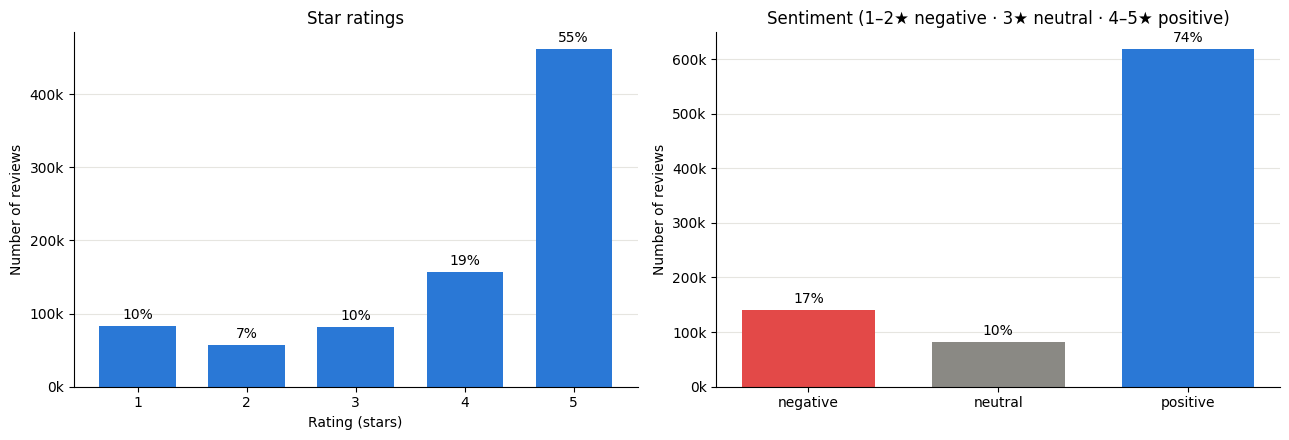

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

rating_counts = train_raw['overall'].value_counts().sort_index()
bars = axes[0].bar(rating_counts.index.astype(str), rating_counts.values, color='#2a78d6', width=0.7)
axes[0].bar_label(bars, labels=[f'{v:.0%}' for v in rating_counts / rating_counts.sum()], padding=3)
axes[0].set(title='Star ratings', xlabel='Rating (stars)', ylabel='Number of reviews')

sent_counts = train_raw['sentiment'].value_counts().reindex(LABELS)
bars = axes[1].bar(LABELS, sent_counts.values, color=[SENTIMENT_COLORS[l] for l in LABELS], width=0.7)
axes[1].bar_label(bars, labels=[f'{v:.0%}' for v in sent_counts / sent_counts.sum()], padding=3)
axes[1].set(title='Sentiment (1–2★ negative · 3★ neutral · 4–5★ positive)', ylabel='Number of reviews')

for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

### Class balance

The data is **heavily imbalanced**: 5-star reviews make up about 55% of the data, and positive reviews about 74%.
A classifier trained on this distribution can get high accuracy by always predicting *positive*, while it ignores minority classes such as neutral.
For the model comparison we therefore **down-sample to a balanced set** (Section 4) and report **macro-averaged** metrics, which weight every class equally.

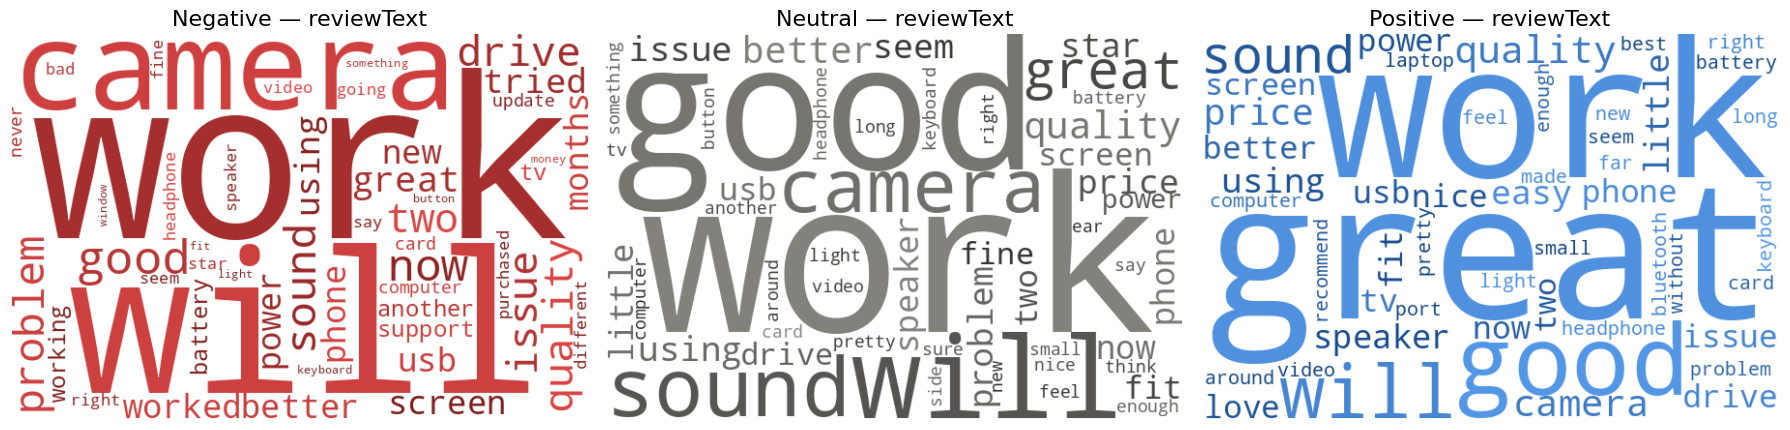

In [7]:
import nltk
from matplotlib.colors import LinearSegmentedColormap
from nltk.stem import WordNetLemmatizer
from wordcloud import STOPWORDS, WordCloud

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
lemmatizer = WordNetLemmatizer()
PUNCT_TABLE = str.maketrans('', '', string.punctuation)

# Generic / domain words that dominate every class and say nothing about sentiment.
WC_STOPWORDS = set(STOPWORDS) | {
    'amazon', 'product', 'use', 'one', 'get', 'used', 'case',
    'make', 'take', 'put', 'go', 'come', 'want', 'would', 'could', 'need', 'buy', 'thing', 'way',
    'see', 'know', 'look', 'got', 'give', 'keep',
    'first', 'second', 'time', 'day', 'month', 'year', 'hour', 'week', 'set', 'lot', 'bit',
    'device', 'unit', 'item', 'part', 'cable', 'plug', 'adapter',
    'review', 'purchase', 'order', 'shipping', 'delivery', 'bought', 'seller', 'arrived',
    'received', 'returned', 'return',
    'im', 'ive', 'cant', 'didnt', 'doesnt', 'dont', 'wasnt', 'isnt', 'arent', 'wont', 'wouldnt',
    'shouldnt', 'br', 'nbsp', 'u', 'n', 'etc', 'also', 'even', 'still', 'much', 'really', 'well',
    'back', 'since', 'however', 'though', 'yet',
}
WC_CMAPS = {
    'negative': LinearSegmentedColormap.from_list('neg', ['#e34948', '#7a1d1c']),
    'neutral': LinearSegmentedColormap.from_list('neu', ['#8a8984', '#2b2b29']),
    'positive': LinearSegmentedColormap.from_list('pos', ['#5598e7', '#104281']),
}


def wc_clean(text, lemmatize=False):
    words = str(text).lower().translate(PUNCT_TABLE).split()
    if lemmatize:
        words = [lemmatizer.lemmatize(w) for w in words]
    return ' '.join(words)


def plot_wordclouds(df, column, lemmatize=False, max_words=50, sample=30_000):
    # One word cloud per sentiment; each class is sampled to keep it fast.
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, sentiment in zip(axes, LABELS):
        texts = df.loc[df['sentiment'] == sentiment, column]
        texts = texts[texts.str.len() > 0]
        texts = texts.sample(min(sample, len(texts)), random_state=SEED)
        wc = WordCloud(width=600, height=400, background_color='white', stopwords=WC_STOPWORDS,
                       colormap=WC_CMAPS[sentiment], max_words=max_words, collocations=False,
                       random_state=SEED).generate(' '.join(texts.map(lambda t: wc_clean(t, lemmatize))))
        ax.imshow(wc, interpolation='bilinear')
        ax.axis('off')
        ax.set_title(f'{sentiment.capitalize()} — {column}', fontsize=16)
    plt.tight_layout()
    plt.show()


plot_wordclouds(train_raw, 'reviewText', max_words=50)

The short **summary** field (lemmatised) separates positive and negative vocabulary more clearly than the full review text:

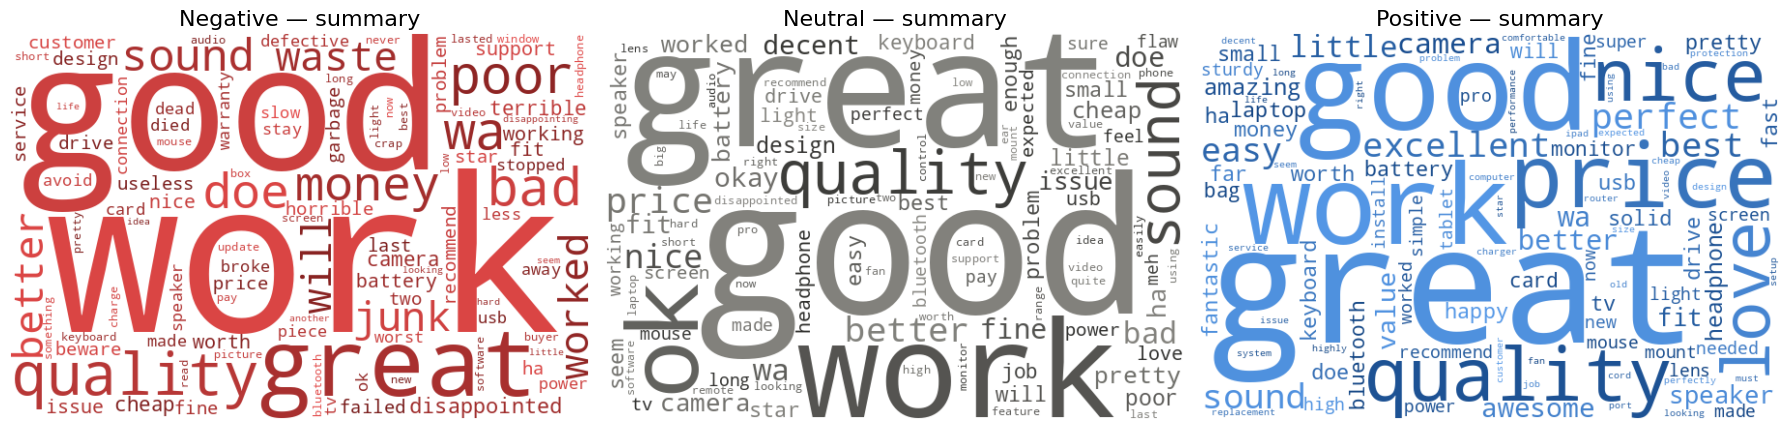

In [8]:
plot_wordclouds(train_raw, 'summary', lemmatize=True, max_words=100)

In [9]:
# Top 10 reviewers by total helpful votes
top_reviewers = (train_raw.groupby('reviewerName')
                 .agg(total_votes=('vote', 'sum'), n_reviews=('vote', 'size'))
                 .nlargest(10, 'total_votes')
                 .reset_index())
top_reviewers

,reviewerName,total_votes,n_reviews
0,Amazon Customer,28871.0,24896
1,Benson Leung,4572.0,29
2,Michael,3710.0,1521
3,Voltron00x,3181.0,9
4,Obi Wan,3150.0,29
5,Mike,3000.0,1774
6,nycebo,2978.0,2
7,Kindle Customer,2927.0,2458
8,John,2730.0,1570
9,Cthulhu,2657.0,53


**Top reviewers.** *Amazon Customer* and *Kindle Customer* are default names that many anonymous users share, so their totals are inflated.
The named reviewers after them (e.g. *Benson Leung*) each collect thousands of helpful votes.
A small group of reviewers produces most of the influential feedback.

In [10]:
# Top 10 products by number of 5-star reviews
top_products = (train_raw[train_raw['overall'] == 5]
                .groupby('asin').size().rename('five_star_count')
                .nlargest(10).reset_index()
                .merge(title_brand, on='asin', how='left'))
top_products['amazon_link'] = 'https://www.amazon.com/dp/' + top_products['asin']
top_products

,asin,five_star_count,title,brand,amazon_link
0,B010OYASRG,1163,OontZ Angle 3 Enhanced Stereo Edition IPX5 Spl...,Cambridge Soundworks,https://www.amazon.com/dp/B010OYASRG
1,B00L0YLRUW,659,NETGEAR N300 WiFi Range Extender (EX2700),NETGEAR,https://www.amazon.com/dp/B00L0YLRUW
2,B01DA0YCNC,600,Roku Streaming Stick (3600R) - HD Streaming Pl...,Roku,https://www.amazon.com/dp/B01DA0YCNC
3,B000VS4HDM,598,StarTech USB 2.0 to SATA IDE Adapter (USB2SATA...,StarTech,https://www.amazon.com/dp/B000VS4HDM
4,B0043T7FXE,552,Logitech M570 Wireless Trackball Mouse &ndash;...,Logitech,https://www.amazon.com/dp/B0043T7FXE
5,B00OBRE5UE,529,Samsung 850 EVO 500GB 2.5-Inch SATA III Intern...,Samsung,https://www.amazon.com/dp/B00OBRE5UE
6,B00S9SGNNS,471,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up...,Asus,https://www.amazon.com/dp/B00S9SGNNS
7,B000WYVBR0,448,VideoSecu ML531BE TV Wall Mount for Most 27&qu...,VideoSecu,https://www.amazon.com/dp/B000WYVBR0
8,B00P7EVST6,433,Arlo - Wireless Home Security Camera System | ...,"Arlo Technologies, Inc",https://www.amazon.com/dp/B00P7EVST6
9,B00OAJ412U,431,Samsung 850 EVO 250GB 2.5-Inch SATA III Intern...,Samsung,https://www.amazon.com/dp/B00OAJ412U


In [11]:
# Top 10 brands by total helpful votes, with their average rating
top_brands = (train_raw.merge(title_brand[['asin', 'brand']], on='asin', how='inner')
              .groupby('brand')
              .agg(total_votes=('vote', 'sum'), mean_rating=('overall', 'mean'), n_reviews=('overall', 'size'))
              .nlargest(10, 'total_votes')
              .round({'mean_rating': 2})
              .reset_index())
top_brands

,brand,total_votes,mean_rating,n_reviews
0,Samsung,55882.0,3.94,15406
1,Sony,38895.0,3.92,11752
2,Asus,29155.0,3.86,11928
3,Canon,24797.0,4.40,4726
4,LG,22099.0,3.87,4697
5,AmazonBasics,18295.0,4.20,13213
6,TP-LINK,17994.0,3.93,9773
7,Acer,17235.0,4.05,3167
8,Dell,15972.0,3.86,5400
9,Logitech,15198.0,3.95,16993


**Brands.** This table shows which brands get the most engagement (helpful votes) and whether customers also rate them highly.
Some brands rank high on votes but have an average rating below 4 (e.g. Asus, LG). Others combine high engagement with high ratings (e.g. Canon, Nikon).

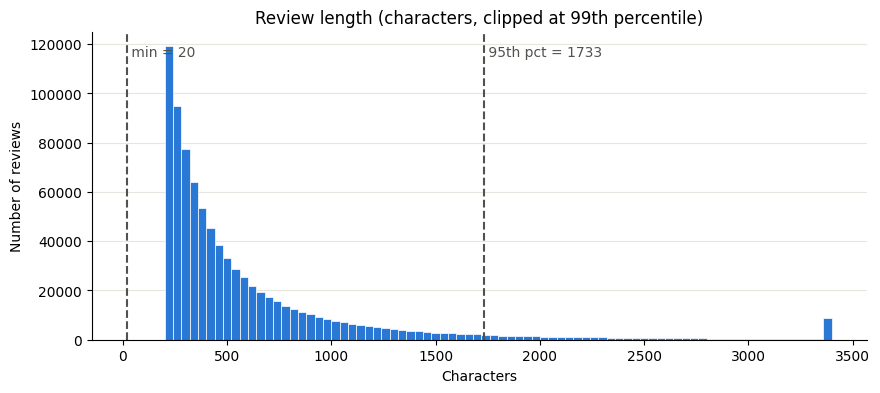

In [12]:
# Review length: shows the length filter used in Section 4
text_length = train_raw['reviewText'].str.len()
LEN_MIN, LEN_MAX = 20, text_length.quantile(0.95)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(text_length.clip(upper=text_length.quantile(0.99)), bins=80, color='#2a78d6', edgecolor='white', linewidth=0.5)
for x, name in [(LEN_MIN, f'min = {LEN_MIN}'), (LEN_MAX, f'95th pct = {LEN_MAX:.0f}')]:
    ax.axvline(x, color='#52514e', linestyle='--', linewidth=1.5)
    ax.text(x, ax.get_ylim()[1] * 0.92, f' {name}', color='#52514e')
ax.set(title='Review length (characters, clipped at 99th percentile)', xlabel='Characters', ylabel='Number of reviews')
plt.show()

### Why limit text length?

* **Compute and memory:** the cost of a transformer grows with sequence length (attention is O(n²)), and the LSTM processes long texts step by step.
* **Fixed input sizes:** models truncate or pad to a maximum length. BERT-family models have a hard limit of 512 tokens.
* **Noise:** very short reviews (< 20 characters) carry almost no signal. Extremely long ones are outliers that dominate batches.

We therefore keep reviews between **20 characters** and the **95th percentile** of length.

## 3. Aspect analysis — satisfaction with warranty & guarantee

We use pretrained **Google News Word2Vec** embeddings to expand the seed terms *warranty* and *guarantee* into their nearest neighbours, which include common misspellings.
We then study the reviews that mention any of these terms.
The same embeddings later initialise the BiLSTM in Section 5.

In [13]:
import gensim.downloader as gensim_api
from gensim.models import KeyedVectors

# Use a local copy if present, otherwise download through gensim (~1.6 GB, cached).
w2v_file = W2V_PATH if W2V_PATH.exists() else gensim_api.load('word2vec-google-news-300', return_path=True)
word_vectors = KeyedVectors.load_word2vec_format(str(w2v_file), binary=True, limit=W2V_LIMIT)
print(f'Loaded {len(word_vectors.index_to_key):,} word vectors of dim {word_vectors.vector_size}')

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Loaded 1,000,000 word vectors of dim 300


In [14]:
SEED_TERMS = ['warranty', 'guarantee']
neighbours = {w for term in SEED_TERMS for w, _ in word_vectors.most_similar(term, topn=30)}

# Keep only single-word spellings of the aspect itself. Word2Vec also returns loosely related
# words ('ensure', 'insure', 'PMP_MP4_Players', ...) that would add many false matches.
ASPECT_STEM = re.compile(r'warr|guar|gura')
keywords = sorted({w.lower() for w in neighbours | set(SEED_TERMS)
                   if '_' not in w and ASPECT_STEM.search(w.lower())})
print('Aspect keywords:', keywords)
print('Discarded neighbours:', sorted(w for w in neighbours if w.lower() not in keywords))

aspect_regex = r'\b(?:' + '|'.join(map(re.escape, keywords)) + r')\b'   # non-capturing group
train_raw['mentions_warranty'] = train_raw['reviewText'].str.contains(aspect_regex, case=False, regex=True)
print(f"\n{train_raw['mentions_warranty'].sum():,} reviews "
      f"({train_raw['mentions_warranty'].mean():.1%}) mention warranty/guarantee")

Aspect keywords: ['guarantee', 'guaranteed', 'guaranteeing', 'guarantees', 'guaranties', 'guarantor', 'guaranty', 'guarentee', 'gurantee', 'guranteed', 'warrantee', 'warrantees', 'warrantied', 'warranties', 'warranty']
Discarded neighbours: ['##-year/###_,###_mile', '#-year/##', '#-year/##_,###_mile', ',###_mile', 'AppleCare', 'AppleCare_Protection_Plan', 'Disclaimer_Past_performance', 'Extended_Warranty', 'Extended_warranties', 'Lifetime_Warranty', 'Limited_Lifetime_Warranty', 'Limited_Warranty', 'Roadside_Assistance', 'anti_perforation_warranty', 'assurance', 'assurances', 'assure', 'assured', 'assures', 'assuring', 'certainty', 'ensure', 'ensured', 'ensures', 'ensuring', 'extended_warranties', 'five-year/##_,###_mile', 'gaurantee', 'iResQ', 'insure', 'ironclad_guarantee', 'lifetime_warranty', 'limited_powertrain_warranty', 'mile_powertrain_warranty', 'powertrain_warranties', 'powertrain_warranty', 'repairers', 'secure', 'unless', 'year/###', 'years/###']

18,209 reviews (2.2%) menti

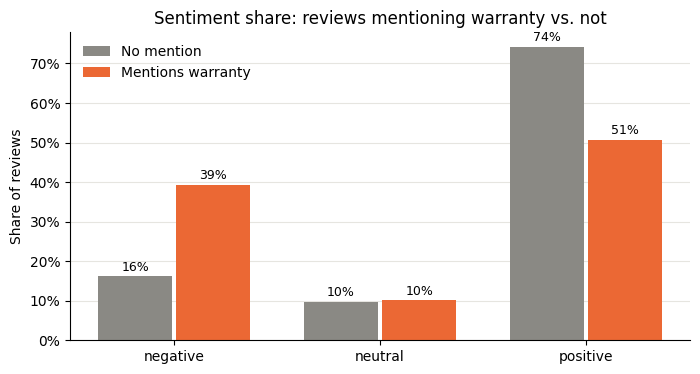

sentiment,negative,neutral,positive
mentions_warranty,,,
No mention,0.162,0.097,0.742
Mentions warranty,0.393,0.101,0.506


In [15]:
# Do reviews that mention warranty/guarantee differ in sentiment?
share = (pd.crosstab(train_raw['mentions_warranty'], train_raw['sentiment'], normalize='index')
         .reindex(columns=LABELS).rename(index={False: 'No mention', True: 'Mentions warranty'}))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(LABELS))
width = 0.38
for i, (group, color) in enumerate(zip(share.index, ['#8a8984', '#eb6834'])):
    bars = ax.bar(x + (i - 0.5) * width, share.loc[group].values, width - 0.02, label=group, color=color)
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in share.loc[group]], padding=2, fontsize=9)
ax.set_xticks(x, LABELS)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(title='Sentiment share: reviews mentioning warranty vs. not', ylabel='Share of reviews')
ax.legend(frameon=False)
plt.show()
share.round(3)

### Product- and brand-level warranty satisfaction

A raw mean rating is unreliable for products with only one or two warranty reviews: one review gives a mean of exactly 1.0 or 5.0.
We use a **Bayesian average**, which pulls the mean toward the global warranty-review mean until enough reviews accumulate:

$$\text{score} = \frac{n\cdot\bar r + m\cdot C}{n + m}$$

Here $n$ is the number of warranty reviews, $\bar r$ is their mean rating, $C$ is the global mean of warranty reviews, and $m$ is the prior strength.

In [16]:
warranty_reviews = (train_raw[train_raw['mentions_warranty']]
                    .assign(is_positive=lambda d: d['sentiment'].eq('positive'),
                            is_negative=lambda d: d['sentiment'].eq('negative'),
                            n_words=lambda d: d['reviewText'].str.split().str.len()))
C = warranty_reviews['overall'].mean()


def bayesian_score(mean, n, m):
    return (n * mean + m * C) / (n + m)


def aspect_summary(df, by, m, min_reviews):
    out = (df.groupby(by)
           .agg(n_reviews=('overall', 'size'), mean_rating=('overall', 'mean'),
                pct_positive=('is_positive', 'mean'), pct_negative=('is_negative', 'mean'),
                mean_helpful_votes=('vote', 'mean'), pct_verified=('verified', 'mean'),
                avg_words=('n_words', 'mean'),
                first_review=('unixReviewTime', 'min'), last_review=('unixReviewTime', 'max')))
    out['warranty_score'] = bayesian_score(out['mean_rating'], out['n_reviews'], m)
    for col in ['pct_positive', 'pct_negative', 'pct_verified']:
        out[col] = (out[col] * 100).round(1)
    for col in ['first_review', 'last_review']:
        out[col] = pd.to_datetime(out[col], unit='s').dt.date
    return out[out['n_reviews'] >= min_reviews].round(2).reset_index()


print(f'Global mean rating of warranty-related reviews: C = {C:.2f}')

product_warranty = (aspect_summary(warranty_reviews, 'asin', m=10, min_reviews=5)
                    .merge(title_brand, on='asin', how='left'))
product_warranty.to_csv(OUTPUT_DIR / 'warranty_product_summary.csv', index=False)

cols = ['title', 'brand', 'n_reviews', 'mean_rating', 'warranty_score', 'pct_positive', 'pct_negative']
print('Products with the most warranty-related reviews:')
display(product_warranty.nlargest(10, 'n_reviews')[cols])
print('Best warranty experience (Bayesian score, ≥5 reviews):')
display(product_warranty.nlargest(10, 'warranty_score')[cols])
print('Worst warranty experience (Bayesian score, ≥5 reviews):')
display(product_warranty.nsmallest(10, 'warranty_score')[cols])

Global mean rating of warranty-related reviews: C = 3.21
Products with the most warranty-related reviews:


,title,brand,n_reviews,mean_rating,warranty_score,pct_positive,pct_negative
460,Microsoft Band 2 - Medium,Microsoft,50,1.68,1.93,6.0,82.0
228,Samsung 850 PRO - 1TB - 2.5-Inch SATA III Inte...,Samsung,47,4.04,3.90,72.3,19.1
149,WD Black 750GB Performance Mobile Hard Disk Dr...,Western Digital,43,4.21,4.02,81.4,16.3
204,Samsung EVO 64GB 48/MB/s Micro SDXC Memory Ca...,Samsung,43,1.77,2.04,11.6,79.1
104,WD Red 8TB NAS Hard Disk Drive - 5400 RPM Clas...,Western Digital,40,3.35,3.32,52.5,35.0
64,"CORSAIR CSM Series, CS550M, 550 Watt, 80+ Gold...",Corsair,35,4.49,4.20,88.6,8.6
305,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up...,Asus,33,2.91,2.98,39.4,45.5
22,Belkin 8-Outlet Power Strip Surge Protector wi...,Belkin,31,3.87,3.71,71.0,19.4
30,APC 11-Outlet Surge Protector 3020 Joules with...,APC,30,4.27,4.00,80.0,6.7
248,iPhone Charger Syncwire Lightning Cable - [App...,Syncwire,29,5.00,4.54,100.0,0.0


Best warranty experience (Bayesian score, ≥5 reviews):


,title,brand,n_reviews,mean_rating,warranty_score,pct_positive,pct_negative
248,iPhone Charger Syncwire Lightning Cable - [App...,Syncwire,29,5.00,4.54,100.0,0.0
64,"CORSAIR CSM Series, CS550M, 550 Watt, 80+ Gold...",Corsair,35,4.49,4.20,88.6,8.6
403,"Anker iPhone Charger, Powerline Lightning Cabl...",Anker,17,4.76,4.19,94.1,0.0
24,Belkin 6-Outlet Pivot-Plug Wall Mount Power St...,Belkin,16,4.75,4.16,87.5,0.0
151,"EVGA 500 B1, 80+ BRONZE 500W Power Supply, 3 Y...",EVGA,25,4.52,4.14,88.0,8.0
183,"EVGA 500 W1, 80+ WHITE 500W, 3 Year Warranty, ...",EVGA,17,4.59,4.08,88.2,5.9
502,Bluetooth Headphones TaoTronics Wireless Earbu...,TaoTronics,16,4.62,4.08,87.5,6.2
157,"EVGA SuperNOVA 1000 P2, 80+ PLATINUM 1000W, Fu...",EVGA,9,5.00,4.06,100.0,0.0
15,Solo Conquer 15.6 Inch Expandable Laptop Messe...,SOLO,12,4.75,4.05,100.0,0.0
306,Anker Tempered Glass Screen Protector for New ...,Anker,11,4.82,4.05,90.9,0.0


Worst warranty experience (Bayesian score, ≥5 reviews):


,title,brand,n_reviews,mean_rating,warranty_score,pct_positive,pct_negative
460,Microsoft Band 2 - Medium,Microsoft,50,1.68,1.93,6.0,82.0
204,Samsung EVO 64GB 48/MB/s Micro SDXC Memory Ca...,Samsung,43,1.77,2.04,11.6,79.1
409,Lexar JumpDrive S45 128GB USB 3.0 Flash Drive ...,Lexar,11,1.09,2.10,0.0,100.0
175,Seagate Backup Plus Slim 2TB Portable Hard Dri...,Seagate,16,1.44,2.12,0.0,93.8
180,VIZIO E500i-B1 50-Inch 1080p Smart LED TV (201...,VIZIO,15,1.40,2.12,6.7,93.3
558,"Samsung Gear Fit2- Pink, Medium/Large",Samsung,22,1.68,2.16,9.1,77.3
75,(Old Model) Seagate 500GB Desktop HDD SATA 6Gb...,Seagate,23,1.74,2.18,8.7,78.3
519,Lexar JumpDrive S45 16GB USB 3.0 Flash Drive -...,Lexar,12,1.33,2.18,8.3,91.7
384,Amcrest ProHD 1080P 4CH Video Home Security Ca...,Amcrest,19,1.68,2.21,5.3,84.2
391,Amcrest ProHD 720P 4CH Video Security System -...,Amcrest,19,1.68,2.21,5.3,84.2


In [17]:
brand_warranty = aspect_summary(warranty_reviews.merge(title_brand[['asin', 'brand']], on='asin', how='inner'),
                                'brand', m=20, min_reviews=20)
brand_warranty.to_csv(OUTPUT_DIR / 'warranty_brand_summary.csv', index=False)

cols = ['brand', 'n_reviews', 'mean_rating', 'warranty_score', 'pct_positive', 'pct_negative', 'mean_helpful_votes']
print('Brands with the most warranty-related reviews:')
display(brand_warranty.nlargest(10, 'n_reviews')[cols])
print('Best brands for warranty satisfaction (≥20 reviews):')
display(brand_warranty.nlargest(10, 'warranty_score')[cols])
print('Worst brands for warranty satisfaction (≥20 reviews):')
display(brand_warranty.nsmallest(10, 'warranty_score')[cols])

Brands with the most warranty-related reviews:


,brand,n_reviews,mean_rating,warranty_score,pct_positive,pct_negative,mean_helpful_votes
110,Samsung,590,2.81,2.83,39.8,51.2,5.80
15,Asus,480,2.61,2.63,32.3,53.5,3.34
121,Sony,357,2.75,2.78,36.7,50.7,4.01
9,Anker,356,4.15,4.10,76.4,13.5,2.11
152,Western Digital,350,3.21,3.21,50.3,39.7,3.83
124,SquareTrade,286,3.27,3.26,52.8,38.8,8.25
66,Logitech,284,2.85,2.88,40.1,49.6,1.50
113,Seagate,277,2.45,2.50,30.3,59.2,1.82
35,Dell,261,2.66,2.70,34.9,52.9,6.06
80,NETGEAR,258,2.55,2.60,33.3,58.1,3.11


Best brands for warranty satisfaction (≥20 reviews):


,brand,n_reviews,mean_rating,warranty_score,pct_positive,pct_negative,mean_helpful_votes
84,Noctua,45,4.96,4.42,100.0,0.0,1.09
127,Syncwire,65,4.74,4.38,93.8,6.2,4.49
37,EVGA,147,4.41,4.27,82.3,8.8,3.00
25,Breakthrough Photography,40,4.78,4.25,95.0,2.5,4.18
150,Vortex Optics,38,4.68,4.17,89.5,2.6,3.50
5,AUKEY,93,4.33,4.13,83.9,11.8,1.53
9,Anker,356,4.15,4.10,76.4,13.5,2.11
158,iXCC,40,4.55,4.10,92.5,7.5,3.22
12,ArmorSuit,31,4.58,4.04,87.1,3.2,1.81
125,StarTech,126,4.17,4.04,81.0,11.9,0.71


Worst brands for warranty satisfaction (≥20 reviews):


,brand,n_reviews,mean_rating,warranty_score,pct_positive,pct_negative,mean_helpful_votes
146,VIZIO,139,1.86,2.03,17.3,75.5,3.02
8,Amcrest,99,2.00,2.20,14.1,75.8,2.23
73,Microsoft,183,2.23,2.33,21.9,64.5,3.51
64,Lexar,75,2.13,2.36,26.7,70.7,1.23
106,Roku,65,2.20,2.44,21.5,63.1,1.83
97,Pioneer,63,2.21,2.45,20.6,61.9,4.68
103,Q-See,26,1.88,2.46,15.4,76.9,1.04
113,Seagate,277,2.45,2.50,30.3,59.2,1.82
119,SmartGuard,61,2.30,2.52,24.6,62.3,5.61
72,Mediasonic,22,2.00,2.57,22.7,72.7,5.00


In [18]:
# Read a few reviews of the worst-scoring product
worst = product_warranty.nsmallest(1, 'warranty_score').iloc[0]
print(f"Worst product: {worst['title']} ({worst['brand']}), asin={worst['asin']}")
(warranty_reviews[warranty_reviews['asin'] == worst['asin']]
 .sort_values('unixReviewTime', ascending=False)
 .head(5)[['overall', 'vote', 'verified', 'summary', 'reviewText']])

Worst product: Microsoft Band 2 - Medium (Microsoft), asin=B0163CHND0


,overall,vote,verified,summary,reviewText
817754,5,0.0,True,Band 2 is still one of the Best fully capable ...,We have used the Band 2 since it was launched....
555393,1,0.0,True,Battery Died after 3 months of use,After 3 months of use the battery died and Mic...
555397,1,0.0,False,Disappointed - bad design on the band.,"At first, I loved this device - interface is g..."
555399,1,0.0,True,Wrist Strap on 4 Bands splits apart.,I love the features of this band but the wris...
555400,1,0.0,True,replaced twice until out of warranty !,I don't know where to start ! lets start with ...


## 4. Shared modelling dataset

Both models get exactly the same data:

1. **Quality filter:** keep `verified == True` purchases (higher signal-to-noise).
2. **Length filter:** keep reviews of 20 characters up to the 95th percentile of length.
3. **Normalisation:** lowercase; remove URLs and HTML; keep letters, digits and `.,!?'$%`; collapse whitespace. Stopwords are **not** removed: *not*, *no* and *never* flip sentiment.
4. **De-duplication:** drop exact duplicate texts, then near-duplicates that share the first and last 40 characters.
5. **Labels:** 1–2★ → negative, 3★ → neutral, 4–5★ → positive.
6. **Balanced sample:** `PER_CLASS` reviews per class.
7. **Stratified split:** 70% train, 15% validation (model selection and early stopping), 15% test (final comparison only).

In [19]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)        # URLs
    text = re.sub(r'<.*?>', ' ', text)                    # HTML tags
    text = re.sub(r"[^a-z0-9$%\s.,!?']", ' ', text)       # keep alphanumerics + basic punctuation
    return re.sub(r'\s+', ' ', text).strip()


df = train_raw.loc[train_raw['verified'] == True, ['reviewText', 'overall', 'sentiment']].copy()
lengths = df['reviewText'].str.len()
df = df[(lengths >= LEN_MIN) & (lengths <= LEN_MAX)]

df['text'] = df['reviewText'].map(clean_text)
df = df[df['text'].str.len() > 0]
df = df.drop_duplicates(subset='text')
df = df[~df.assign(start=df['text'].str[:40], end=df['text'].str[-40:]).duplicated(subset=['start', 'end'])]
df['label'] = df['sentiment'].map(LABEL2ID)
print(f'{len(df):,} clean reviews. Class counts:', df['sentiment'].value_counts().to_dict())

n_per_class = min(PER_CLASS, df['label'].value_counts().min())
model_df = (df.groupby('label').sample(n=n_per_class, random_state=SEED)
            .sample(frac=1, random_state=SEED)[['text', 'label']]
            .reset_index(drop=True))

train_df, temp_df = train_test_split(model_df, test_size=VAL_SIZE + TEST_SIZE,
                                     stratify=model_df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
                                   stratify=temp_df['label'], random_state=SEED)
print(f'train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}  ({n_per_class:,} per class)')

del df, temp_df
gc.collect()
train_df.head()

667,716 clean reviews. Class counts: {'positive': 494014, 'negative': 109133, 'neutral': 64569}
train=10,500  val=2,250  test=2,250  (5,000 per class)


,text,label
6252,"great useful accessorie, well built and easy t...",2
8156,purchased to replace ddr3 ram that had been cr...,2
11572,i bought this more to use as a speakerphone fo...,2
3454,"it works in occasions, meaning quite frequentl...",1
5162,the bluetooth connectivity is better than expe...,2


In [20]:
# Shared evaluation helpers
RESULTS = {}       # model name -> test metrics
TEST_PREDS = {}    # model name -> predicted label ids on test_df


def score(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'macro_precision': p, 'macro_recall': r,
            'macro_f1': f1, 'qwk': cohen_kappa_score(y_true, y_pred, weights='quadratic')}


def plot_confusion(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(LABELS)), normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, linewidths=2, linecolor='white', ax=ax)
    ax.set(title=title, xlabel='Predicted', ylabel='True')
    ax.grid(False)


def plot_history(history, title):
    # history: DataFrame with columns epoch, train_loss, val_loss, val_macro_f1
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history['epoch'], history['train_loss'], marker='o', lw=2, color='#2a78d6', label='train')
    axes[0].plot(history['epoch'], history['val_loss'], marker='o', lw=2, color='#eb6834', label='validation')
    axes[0].set(title=f'{title} — loss', xlabel='Epoch', ylabel='Loss')
    axes[0].legend(frameon=False)
    axes[1].plot(history['epoch'], history['val_macro_f1'], marker='o', lw=2, color='#eb6834')
    axes[1].set(title=f'{title} — validation macro F1', xlabel='Epoch', ylabel='Macro F1')
    for ax in axes:
        ax.set_xticks(history['epoch'])
    plt.tight_layout()
    plt.show()


def report(name, y_true, y_pred, train_time, n_params):
    RESULTS[name] = {**score(y_true, y_pred), 'train_time_min': train_time / 60, 'params_M': n_params / 1e6}
    TEST_PREDS[name] = np.asarray(y_pred)
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=3))
    fig, ax = plt.subplots(figsize=(4.5, 4))
    plot_confusion(ax, y_true, y_pred, f'{name} — test set')
    plt.show()

## 5. Model A — BiLSTM + Word2Vec

* **Vocabulary:** the 20k most frequent tokens of the **training split only** (no leakage from validation or test).
* **Embeddings:** initialised from Google News Word2Vec (300-d) and fine-tuned; unknown words start random.
* **Architecture:** a bidirectional LSTM over packed sequences, so padding is never processed. Then **masked** mean- and max-pooling, followed by an MLP head with 3 outputs.
* **Training:** AdamW, label smoothing 0.1 (the same as DistilBERT), gradient clipping, LR reduced on plateau, early stopping on validation macro F1.

In [21]:
TOKEN_RE = re.compile(r"[a-z0-9']+")
tokenize = TOKEN_RE.findall

VOCAB_SIZE = 20_000
PAD, UNK = 0, 1
train_tokens = train_df['text'].map(tokenize)
counter = Counter(tok for toks in train_tokens for tok in toks)
itos = ['<pad>', '<unk>'] + [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]
stoi = {w: i for i, w in enumerate(itos)}

token_counts = train_tokens.map(len)
LSTM_MAX_LEN = int(min(256, np.percentile(token_counts, 95)))
print(f'Vocabulary: {len(itos):,} | words per review: median={token_counts.median():.0f}, '
      f'95th pct={np.percentile(token_counts, 95):.0f} -> LSTM_MAX_LEN={LSTM_MAX_LEN}')


def encode(text, max_len=LSTM_MAX_LEN):
    ids = [stoi.get(t, UNK) for t in tokenize(text)[:max_len]]
    return ids + [PAD] * (max_len - len(ids))


# Embedding matrix from Word2Vec (Google News is case-sensitive: try lowercase, then Title case)
EMB_DIM = word_vectors.vector_size
rng = np.random.default_rng(SEED)
embedding_matrix = rng.normal(0, 0.05, size=(len(itos), EMB_DIM)).astype(np.float32)
embedding_matrix[PAD] = 0
found = 0
for word, idx in stoi.items():
    for candidate in (word, word.title()):
        if candidate in word_vectors.key_to_index:
            embedding_matrix[idx] = word_vectors[candidate]
            found += 1
            break
print(f'Word2Vec coverage: {found:,}/{len(itos):,} ({found / len(itos):.1%})')

# The 3.6 GB Word2Vec model is no longer needed
del word_vectors
gc.collect()

Vocabulary: 20,000 | words per review: median=74, 95th pct=219 -> LSTM_MAX_LEN=219
Word2Vec coverage: 15,287/20,000 (76.4%)


0

In [22]:
class SequenceDataset(TorchDataset):
    def __init__(self, texts, labels=None):
        self.x = torch.tensor([encode(t) for t in texts], dtype=torch.long)
        self.y = torch.tensor(np.asarray(labels) if labels is not None else np.zeros(len(self.x)), dtype=torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim=128, num_classes=3, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.from_numpy(embedding_matrix), freeze=False, padding_idx=PAD)
        self.lstm = nn.LSTM(embedding_matrix.shape[1], hidden_dim, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(4 * hidden_dim, 128), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x):
        lengths = (x != PAD).sum(1).clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(self.embedding(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (torch.arange(x.size(1), device=x.device)[None, :] < lengths[:, None]).unsqueeze(-1)
        mean_pool = (out * mask).sum(1) / lengths[:, None]
        max_pool = out.masked_fill(~mask, -1e4).max(1).values
        return self.head(torch.cat([mean_pool, max_pool], dim=1))


@torch.no_grad()
def lstm_predict_proba(model, texts, batch_size=256):
    model.eval()
    loader = DataLoader(SequenceDataset(list(texts)), batch_size=batch_size)
    return torch.cat([torch.softmax(model(xb.to(DEVICE)), -1).cpu() for xb, _ in loader]).numpy()


BATCH_SIZE = 64
train_loader = DataLoader(SequenceDataset(train_df['text'], train_df['label']), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SequenceDataset(val_df['text'], val_df['label']), batch_size=256)

set_seed()
lstm_model = BiLSTMClassifier(embedding_matrix).to(DEVICE)
lstm_params = sum(p.numel() for p in lstm_model.parameters())
print(lstm_model)
print(f'Parameters: {lstm_params / 1e6:.2f}M')

BiLSTMClassifier(
  (embedding): Embedding(20000, 300, padding_idx=0)
  (lstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=3, bias=True)
  )
)
Parameters: 6.51M


epoch  1 | train_loss 0.9954 | val_loss 0.8621 | val_acc 0.6244 | val_macro_f1 0.6272
epoch  2 | train_loss 0.7984 | val_loss 0.8253 | val_acc 0.6547 | val_macro_f1 0.6597
epoch  3 | train_loss 0.6747 | val_loss 0.8737 | val_acc 0.6480 | val_macro_f1 0.6429
epoch  4 | train_loss 0.5786 | val_loss 0.9153 | val_acc 0.6409 | val_macro_f1 0.6350
epoch  5 | train_loss 0.4612 | val_loss 0.9658 | val_acc 0.6413 | val_macro_f1 0.6423
Early stopping (no improvement for 3 epochs)
Best val macro F1 = 0.6597 | training time 0.6 min


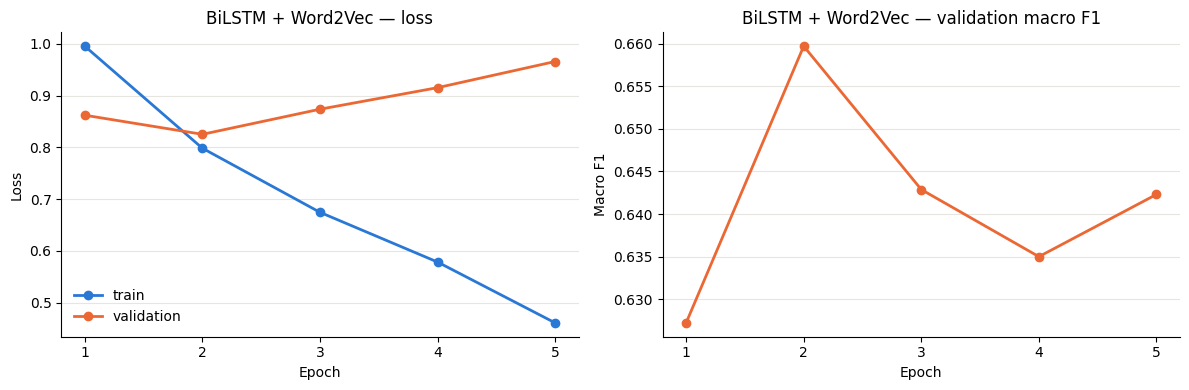

In [23]:
NUM_EPOCHS, PATIENCE = 10, 3
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(lstm_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, preds, labels = 0.0, [], []
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            preds.append(logits.argmax(-1).cpu())
            labels.append(yb.cpu())
    labels, preds = torch.cat(labels).numpy(), torch.cat(preds).numpy()
    return total_loss / len(labels), score(labels, preds)


history, best_f1, best_state, bad_epochs = [], -1.0, None, 0
start = time.perf_counter()
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, _ = run_epoch(lstm_model, train_loader, optimizer)
    val_loss, val_scores = run_epoch(lstm_model, val_loader)
    scheduler.step(val_scores['macro_f1'])
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss, 'val_macro_f1': val_scores['macro_f1']})
    print(f"epoch {epoch:2d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | "
          f"val_acc {val_scores['accuracy']:.4f} | val_macro_f1 {val_scores['macro_f1']:.4f}")
    if val_scores['macro_f1'] > best_f1:
        best_f1, bad_epochs = val_scores['macro_f1'], 0
        best_state = {k: v.detach().cpu().clone() for k, v in lstm_model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f'Early stopping (no improvement for {PATIENCE} epochs)')
            break
lstm_train_time = time.perf_counter() - start

lstm_model.load_state_dict(best_state)
torch.save(best_state, OUTPUT_DIR / 'best_bilstm.pt')
print(f'Best val macro F1 = {best_f1:.4f} | training time {lstm_train_time / 60:.1f} min')
plot_history(pd.DataFrame(history), 'BiLSTM + Word2Vec')

              precision    recall  f1-score   support

    negative      0.677     0.715     0.695       750
     neutral      0.547     0.632     0.587       750
    positive      0.848     0.669     0.748       750

    accuracy                          0.672      2250
   macro avg      0.691     0.672     0.677      2250
weighted avg      0.691     0.672     0.677      2250



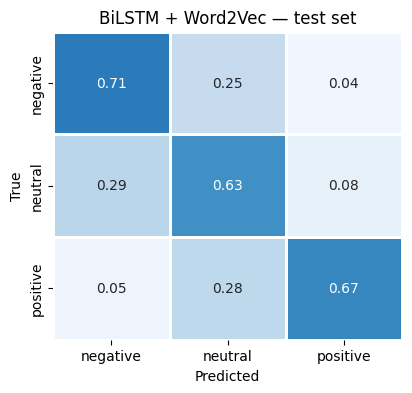

In [24]:
lstm_test_proba = lstm_predict_proba(lstm_model, test_df['text'])
report('BiLSTM + Word2Vec', test_df['label'].values, lstm_test_proba.argmax(-1), lstm_train_time, lstm_params)

## 6. Model B — DistilBERT

`distilbert-base-uncased` gets a 3-way classification head and is fine-tuned with the Hugging Face `Trainer`.
The Trainer evaluates on the **validation** split after every epoch and reloads the checkpoint with the best validation macro F1.

In [25]:
from datasets import Dataset as HFDataset
from datasets import DatasetDict
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments)
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()      # silences the "sequence longer than 512" notice during length analysis
BERT_MODEL = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)

# Choose max_length from the token-length distribution of the training split
bert_lengths = np.array([len(ids) for ids in tokenizer(train_df['text'].tolist(), truncation=False)['input_ids']])
print('Token-length percentiles:', {p: int(np.percentile(bert_lengths, p)) for p in [50, 75, 90, 95, 99]})
for L in [128, 256, 384, 512]:
    print(f'  max_length={L}: {(bert_lengths > L).mean():.1%} of reviews truncated')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Token-length percentiles: {50: 90, 75: 140, 90: 215, 95: 264, 99: 353}
  max_length=128: 29.1% of reviews truncated
  max_length=256: 5.5% of reviews truncated
  max_length=384: 0.2% of reviews truncated
  max_length=512: 0.0% of reviews truncated


In [26]:
BERT_MAX_LEN = 256    # truncates only a small share of reviews (see above) at half the cost of 512

raw_ds = DatasetDict({name: HFDataset.from_pandas(split.reset_index(drop=True))
                      for name, split in [('train', train_df), ('validation', val_df), ('test', test_df)]})


def tokenize_batch(batch):
    return tokenizer(batch['text'], truncation=True, max_length=BERT_MAX_LEN)


tok_ds = raw_ds.map(tokenize_batch, batched=True, remove_columns=['text'])
tok_ds

Map:   0%|          | 0/10500 [00:00<?, ? examples/s]

Map:   0%|          | 0/2250 [00:00<?, ? examples/s]

Map:   0%|          | 0/2250 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 10500
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2250
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2250
    })
})

### Metrics

* **Accuracy:** the share of correct predictions.
* **Macro precision / recall / F1:** the per-class metric averaged with equal weight, so no class can dominate.
* **Quadratic Weighted Kappa (QWK):** agreement for **ordinal** labels. Confusing *negative* with *positive* costs more than confusing *negative* with *neutral*, which suits the ordered classes negative < neutral < positive.

In [27]:
def hf_compute_metrics(eval_pred):
    logits, labels = eval_pred
    return score(labels, np.argmax(logits, axis=-1))


set_seed()
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID)
bert_params = sum(p.numel() for p in bert_model.parameters())

BERT_EPOCHS, BERT_BATCH = 3, 32
total_steps = int(np.ceil(len(tok_ds['train']) / BERT_BATCH)) * BERT_EPOCHS

args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / 'distilbert'),
    num_train_epochs=BERT_EPOCHS,
    per_device_train_batch_size=BERT_BATCH,
    per_device_eval_batch_size=128,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=int(0.1 * total_steps),
    label_smoothing_factor=0.1,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to='none',
    seed=SEED,
)

trainer = Trainer(
    model=bert_model,
    args=args,
    train_dataset=tok_ds['train'],
    eval_dataset=tok_ds['validation'],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=hf_compute_metrics,
)

start = time.perf_counter()
trainer.train()
bert_train_time = time.perf_counter() - start
print(f'Parameters: {bert_params / 1e6:.1f}M | training time {bert_train_time / 60:.1f} min')

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '1.096', 'grad_norm': '1.147', 'learning_rate': '1e-05', 'epoch': '0.152'}
{'loss': '0.9836', 'grad_norm': '6.044', 'learning_rate': '1.998e-05', 'epoch': '0.304'}
{'loss': '0.7941', 'grad_norm': '4.773', 'learning_rate': '1.885e-05', 'epoch': '0.4559'}
{'loss': '0.7949', 'grad_norm': '4.829', 'learning_rate': '1.773e-05', 'epoch': '0.6079'}
{'loss': '0.7671', 'grad_norm': '4.508', 'learning_rate': '1.66e-05', 'epoch': '0.7599'}
{'loss': '0.7436', 'grad_norm': '3.93', 'learning_rate': '1.548e-05', 'epoch': '0.9119'}
{'eval_loss': '0.7356', 'eval_accuracy': '0.7218', 'eval_macro_precision': '0.7215', 'eval_macro_recall': '0.7218', 'eval_macro_f1': '0.7183', 'eval_qwk': '0.7428', 'eval_runtime': '4.309', 'eval_samples_per_second': '522.2', 'eval_steps_per_second': '4.178', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.7053', 'grad_norm': '4.041', 'learning_rate': '1.435e-05', 'epoch': '1.064'}
{'loss': '0.6827', 'grad_norm': '3.763', 'learning_rate': '1.323e-05', 'epoch': '1.216'}
{'loss': '0.6815', 'grad_norm': '7.384', 'learning_rate': '1.21e-05', 'epoch': '1.368'}
{'loss': '0.6829', 'grad_norm': '6.957', 'learning_rate': '1.098e-05', 'epoch': '1.52'}
{'loss': '0.6599', 'grad_norm': '5.32', 'learning_rate': '9.854e-06', 'epoch': '1.672'}
{'loss': '0.6597', 'grad_norm': '2.842', 'learning_rate': '8.729e-06', 'epoch': '1.824'}
{'loss': '0.6494', 'grad_norm': '5.595', 'learning_rate': '7.604e-06', 'epoch': '1.976'}
{'eval_loss': '0.7408', 'eval_accuracy': '0.7196', 'eval_macro_precision': '0.7184', 'eval_macro_recall': '0.7196', 'eval_macro_f1': '0.7095', 'eval_qwk': '0.7457', 'eval_runtime': '5.171', 'eval_samples_per_second': '435.1', 'eval_steps_per_second': '3.481', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.6041', 'grad_norm': '5.717', 'learning_rate': '6.479e-06', 'epoch': '2.128'}
{'loss': '0.5631', 'grad_norm': '4.645', 'learning_rate': '5.354e-06', 'epoch': '2.28'}
{'loss': '0.6018', 'grad_norm': '6.488', 'learning_rate': '4.229e-06', 'epoch': '2.432'}
{'loss': '0.6011', 'grad_norm': '3.116', 'learning_rate': '3.105e-06', 'epoch': '2.584'}
{'loss': '0.5961', 'grad_norm': '5.584', 'learning_rate': '1.98e-06', 'epoch': '2.736'}
{'loss': '0.5923', 'grad_norm': '6.743', 'learning_rate': '8.549e-07', 'epoch': '2.888'}
{'eval_loss': '0.7327', 'eval_accuracy': '0.74', 'eval_macro_precision': '0.7418', 'eval_macro_recall': '0.74', 'eval_macro_f1': '0.7408', 'eval_qwk': '0.7643', 'eval_runtime': '4.675', 'eval_samples_per_second': '481.3', 'eval_steps_per_second': '3.85', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '243.1', 'train_samples_per_second': '129.6', 'train_steps_per_second': '4.06', 'train_loss': '0.7035', 'epoch': '3'}
Parameters: 67.0M | training time 4.1 min


,epoch,train_loss,val_loss,val_macro_f1
0,1,0.8632,0.7356,0.7183
1,2,0.6745,0.7408,0.7095
2,3,0.5931,0.7327,0.7408


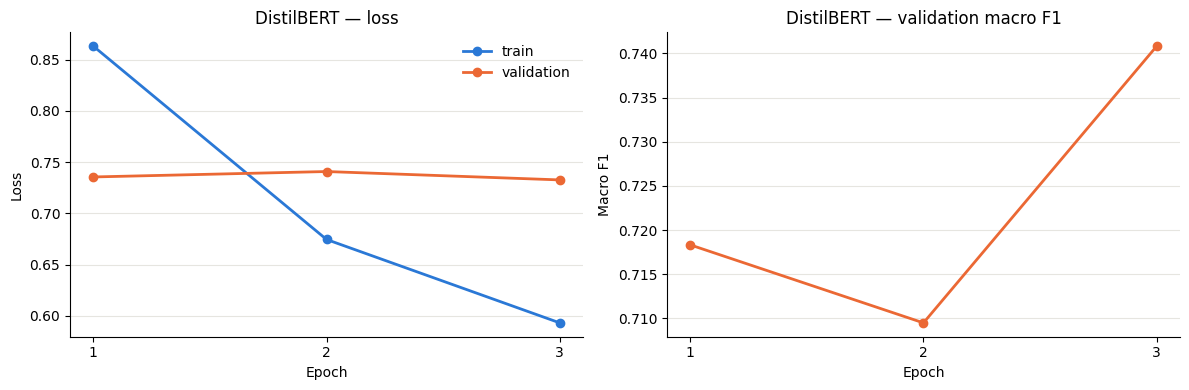

In [28]:
# Learning curves: per-epoch train loss (mean of the logged steps) vs. validation metrics
logs = pd.DataFrame(trainer.state.log_history)
train_loss = (logs.dropna(subset=['loss']).assign(epoch=lambda d: np.ceil(d['epoch']).astype(int))
              .groupby('epoch')['loss'].mean())
eval_logs = logs.dropna(subset=['eval_loss']).assign(epoch=lambda d: d['epoch'].round().astype(int)).set_index('epoch')
bert_history = pd.DataFrame({'train_loss': train_loss, 'val_loss': eval_logs['eval_loss'],
                             'val_macro_f1': eval_logs['eval_macro_f1']}).dropna().reset_index(names='epoch')
display(bert_history.round(4))
plot_history(bert_history, 'DistilBERT')

If the validation loss rises while the training loss keeps falling, the model is **over-fitting**.
`load_best_model_at_end=True` protects us here: the checkpoint we evaluate is the one with the best validation macro F1, not the last one.

              precision    recall  f1-score   support

    negative      0.753     0.739     0.746       750
     neutral      0.640     0.647     0.643       750
    positive      0.840     0.847     0.843       750

    accuracy                          0.744      2250
   macro avg      0.744     0.744     0.744      2250
weighted avg      0.744     0.744     0.744      2250



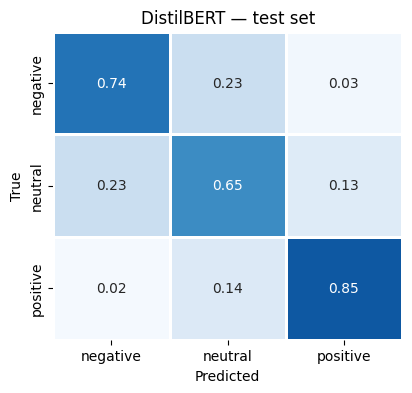

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [29]:
bert_test_output = trainer.predict(tok_ds['test'])
bert_test_proba = torch.softmax(torch.tensor(bert_test_output.predictions), -1).numpy()
report('DistilBERT', test_df['label'].values, bert_test_proba.argmax(-1), bert_train_time, bert_params)

trainer.save_model(str(OUTPUT_DIR / 'best_distilbert'))

## 7. Comparison — DistilBERT vs. BiLSTM + Word2Vec (same test set)

In [30]:
results_df = pd.DataFrame(RESULTS).T
display(results_df.style.format('{:.3f}').highlight_max(
    subset=['accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'qwk'], axis=0, props='font-weight:bold'))

,accuracy,macro_precision,macro_recall,macro_f1,qwk,train_time_min,params_M
BiLSTM + Word2Vec,0.672,0.691,0.672,0.677,0.671,0.576,6.506
DistilBERT,0.744,0.744,0.744,0.744,0.769,4.063,66.956


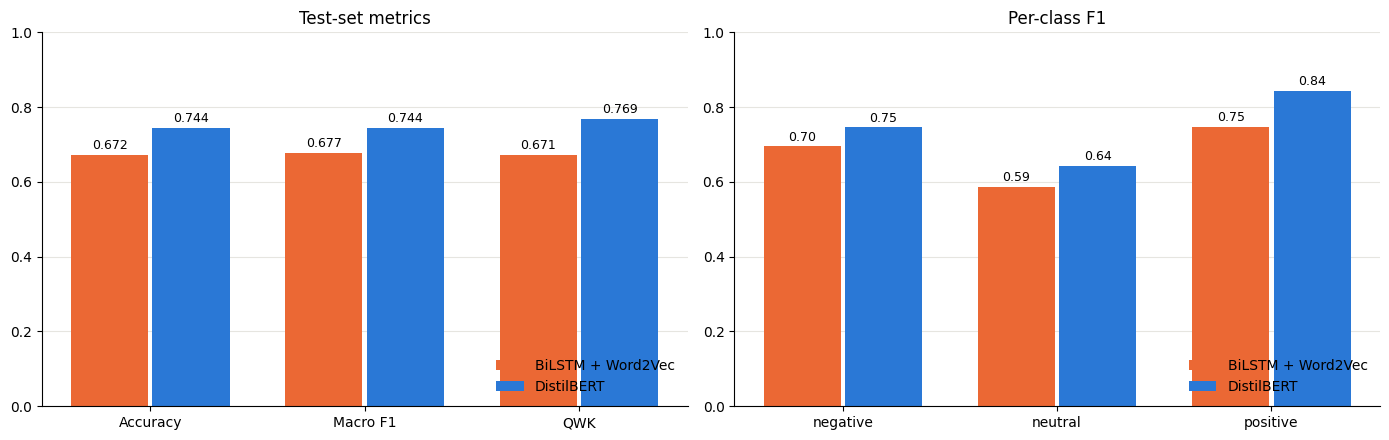

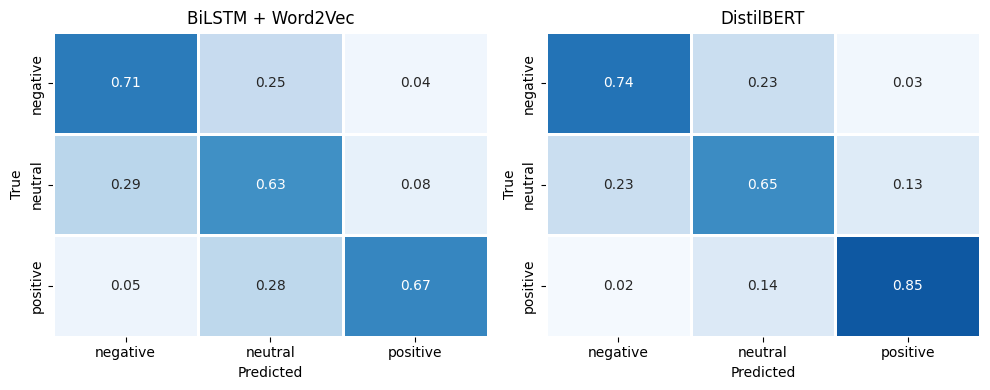

In [31]:
models = list(RESULTS)
y_test = test_df['label'].values

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) headline metrics
metrics = ['accuracy', 'macro_f1', 'qwk']
x = np.arange(len(metrics))
width = 0.38
for i, m in enumerate(models):
    vals = [RESULTS[m][k] for k in metrics]
    bars = axes[0].bar(x + (i - 0.5) * width, vals, width - 0.02, label=m, color=MODEL_COLORS[m])
    axes[0].bar_label(bars, fmt='%.3f', padding=2, fontsize=9)
axes[0].set_xticks(x, ['Accuracy', 'Macro F1', 'QWK'])
axes[0].set(ylim=(0, 1), title='Test-set metrics')
axes[0].legend(frameon=False, loc='lower right')

# (b) per-class F1
x = np.arange(len(LABELS))
for i, m in enumerate(models):
    _, _, f1, _ = precision_recall_fscore_support(y_test, TEST_PREDS[m], labels=range(len(LABELS)), zero_division=0)
    bars = axes[1].bar(x + (i - 0.5) * width, f1, width - 0.02, label=m, color=MODEL_COLORS[m])
    axes[1].bar_label(bars, fmt='%.2f', padding=2, fontsize=9)
axes[1].set_xticks(x, LABELS)
axes[1].set(ylim=(0, 1), title='Per-class F1')
axes[1].legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, m in zip(axes, models):
    plot_confusion(ax, y_test, TEST_PREDS[m], m)
plt.tight_layout()
plt.show()

In [32]:
# Where do the models disagree?
lstm_pred, bert_pred = TEST_PREDS['BiLSTM + Word2Vec'], TEST_PREDS['DistilBERT']
agree = lstm_pred == bert_pred
print(f'Models agree on {agree.mean():.1%} of test reviews')
print(f'  accuracy where they agree:    {(bert_pred[agree] == y_test[agree]).mean():.3f}')
print(f'  DistilBERT right, LSTM wrong: {((bert_pred == y_test) & (lstm_pred != y_test)).sum()}')
print(f'  LSTM right, DistilBERT wrong: {((lstm_pred == y_test) & (bert_pred != y_test)).sum()}')
print(f'  both wrong:                   {((lstm_pred != y_test) & (bert_pred != y_test)).sum()}')

disagreements = test_df.assign(true=test_df['label'].map(ID2LABEL),
                               lstm=pd.Series(lstm_pred, index=test_df.index).map(ID2LABEL),
                               bert=pd.Series(bert_pred, index=test_df.index).map(ID2LABEL))[~agree]
with pd.option_context('display.max_colwidth', 300):
    display(disagreements.sample(min(8, len(disagreements)), random_state=SEED)[['text', 'true', 'lstm', 'bert']])

Models agree on 71.9% of test reviews
  accuracy where they agree:    0.801
  DistilBERT right, LSTM wrong: 379
  LSTM right, DistilBERT wrong: 217
  both wrong:                   359


,text,true,lstm,bert
7485,"overall, love this light. my friend has the dynalite strobe with similar features, 600ws, hss, ttl, same battery mah capacity, etc. however, this unit is much smaller than his! prior to using this strobe, i've been shooting outdoors often at very wide apertures f1.4 f2.0 . in order to use my ali...",neutral,neutral,positive
7132,"i switched from panasonic to sony after reading good reviews for this particular model. the good it takes good pictures. the bad the back side is crowded with too many buttons, with no space to rest the right hand thumb when holding the camera and i have a small thumb! . i often find myself push...",neutral,neutral,negative
6375,i bought this briefcase to replace a nylon messenger bag that i have been using for about 2 years. there are a lot of good points about this briefcase. first the buckles feature snaps so that you can quickly open the compartments without having to worry about them working loose on their own. the...,neutral,neutral,positive
13537,"i mean, it does what it says it does and does it very easily, however the audio is terrible. it lacks any semblance of lows with any settings and it has very low audio output. is it worth it for $8? sure if you have no other choices.",negative,negative,neutral
2065,"just setting up so i will update after it's all up and running. before i bought this, another reviewer pointed out the the difficulty in removing the sd card. same problem here. the pop out spring doesn't work so i'll have to dig it out with tweezers the other reviewer used a sewing needle . it ...",positive,negative,neutral
7011,decent quality banana plugs but give no indication of how you are to connect the speaker wire to the plugs. a google search revealed the answer bu it would be nice to include a little instruction on their use.,neutral,positive,neutral
13602,"overall, a good little bluetooth keyboard. i use my as a remote for my nuc, which i have connected to my tv as a media server. the power switch was flaky for a while, but seems to have found a rhythm...still feels like it's going to fail, but it doesn't. the keys are pretty small, the trackpad i...",neutral,neutral,positive
13610,"as expected. oem battery that my wife and i use as a backup when we are out taking lots of photos. this allows us to never miss a photo opportunity. these batteries last a very long time too. we traveled to greece for 2 weeks and took over 2,000 photos and only had to change the battery out once!",positive,neutral,positive


### Interpretation guide

Read the conclusions from the tables and plots above. Things to look at:

* **Overall quality.** Macro F1 and QWK are the fairest headline numbers on this balanced 3-class task. A transformer usually beats the LSTM because its contextual embeddings capture negation, contrast (*"good at first, but…"*) and sarcasm better than static Word2Vec vectors.
* **The neutral class** is the hardest for both models. A 3-star review mixes praise and complaints, and the per-class F1 and the confusion matrices show neutral confused with both neighbours. Errors between *negative* and *positive* should be rare. QWK rewards exactly this behaviour.
* **Cost.** DistilBERT has about 66M parameters; the BiLSTM has a few million, most of them in the embedding table. The BiLSTM trains much faster and runs cheaply on a CPU. Whether the accuracy gain is worth the cost depends on deployment constraints.
* **Disagreements.** The table above shows typical cases where one model succeeds. Long, mixed-tone reviews tend to favour DistilBERT.

**Possible improvements:** train on more data (raise `PER_CLASS`), prepend the `summary` field to the review text, use a larger model (`roberta-base`), tune the learning rate and number of epochs, or treat the 5-star rating as an ordinal regression target.

## 8. Inference on the unlabeled `test_data.csv`

`test_data.csv` has no ratings, so it can't be scored. We predict its sentiment with both models and save the predictions.

In [33]:
test_texts = test_raw['reviewText'].map(clean_text).tolist()

lstm_unlabeled = lstm_predict_proba(lstm_model, test_texts)
unlabeled_ds = HFDataset.from_dict({'text': test_texts}).map(tokenize_batch, batched=True, remove_columns=['text'])
bert_unlabeled = torch.softmax(torch.tensor(trainer.predict(unlabeled_ds).predictions), -1).numpy()

predictions = pd.DataFrame({
    'reviewerID': test_raw['reviewerID'],
    'asin': test_raw['asin'],
    'lstm_sentiment': pd.Series(lstm_unlabeled.argmax(-1)).map(ID2LABEL),
    'lstm_confidence': lstm_unlabeled.max(-1).round(4),
    'bert_sentiment': pd.Series(bert_unlabeled.argmax(-1)).map(ID2LABEL),
    'bert_confidence': bert_unlabeled.max(-1).round(4),
})
predictions.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

print(f"Saved {len(predictions):,} predictions to {OUTPUT_DIR / 'test_predictions.csv'}")
print(f"Model agreement on unlabeled data: {(predictions['lstm_sentiment'] == predictions['bert_sentiment']).mean():.1%}")
pd.DataFrame({'BiLSTM + Word2Vec': predictions['lstm_sentiment'].value_counts(normalize=True),
              'DistilBERT': predictions['bert_sentiment'].value_counts(normalize=True)}).reindex(LABELS).round(3)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Saved 20,000 predictions to /content/outputs/test_predictions.csv
Model agreement on unlabeled data: 71.3%


,BiLSTM + Word2Vec,DistilBERT
negative,0.355,0.348
neutral,0.385,0.309
positive,0.260,0.343


In [34]:
def predict_sentiment(texts):
    # Classify raw review strings with both models.
    cleaned = [clean_text(t) for t in texts]
    lstm_p = lstm_predict_proba(lstm_model, cleaned)
    enc = tokenizer(cleaned, truncation=True, max_length=BERT_MAX_LEN, padding=True, return_tensors='pt').to(trainer.model.device)
    trainer.model.eval()
    with torch.no_grad():
        bert_p = torch.softmax(trainer.model(**enc).logits, -1).cpu().numpy()
    return pd.DataFrame({'text': texts,
                         'lstm': [f'{ID2LABEL[i]} ({p.max():.2f})' for i, p in zip(lstm_p.argmax(-1), lstm_p)],
                         'bert': [f'{ID2LABEL[i]} ({p.max():.2f})' for i, p in zip(bert_p.argmax(-1), bert_p)]})


predict_sentiment([
    'Works perfectly, great sound quality and the battery lasts forever!',
    'It is okay. Does the job but the build quality feels cheap.',
    'Stopped working after two weeks and the warranty claim was a nightmare.',
    'Not bad at all, I was expecting much worse for the price.',
])

,text,lstm,bert
0,"Works perfectly, great sound quality and the b...",positive (0.91),positive (0.94)
1,It is okay. Does the job but the build quality...,neutral (0.77),neutral (0.87)
2,Stopped working after two weeks and the warran...,negative (0.98),negative (0.92)
3,"Not bad at all, I was expecting much worse for...",negative (0.90),negative (0.47)
